# HeatAhead: weather and property complaint analysis

**Goal:** measure how recorded heating complaints change with cold weather, compare property groups,
and create a weather-specific complaint history for each property.

Use Python 3 in Jupyter with pandas, numpy, and matplotlib. Run cells from top to bottom with **Shift+Enter**.
Put these three inputs beside the notebook, or in a nearby `HeatAhead_weather_2017_onward/` or `data/` folder:

- `days.csv`: observed daily weather and citywide complaint totals.
- `buildings.csv`: property characteristics, including properties with no complaints.
- `bbl_day_counts.csv`: one row per BBL and complaint date, with distinct qualifying complaint IDs counted
  in `complaint_count`. This file contains positive-count dates only.

The dated input was prepared from `NO HEAT` and `NO HEAT AND NO HOT WATER` reports.
Daily raw-source totals were reconciled against `days.csv`; reports without a usable BBL are excluded from property analysis.
All five boroughs are included. A **BBL identifies a property/lot**, which can contain more than one physical building.

For these inputs, dates run from 2017-07-01 through 2026-10-12. Property comparisons use **October–May** dates
and **167,011 properties with known construction years before 2017**. We assume continued activity and source coverage;
the current property snapshot does not establish historical coverage or the historical size of each property.

Outputs are saved in `analysis_outputs/`. The final cell saves a methods note for the 19 result files.
Upload this notebook alongside the outputs to preserve the code. The previously downloaded ZIP is a separate handoff copy.

## 1. Load the inputs

**What this does:** reads the daily file and property list, preserving BBLs as text.
**Why:** the weather dates supply exposure days, and the full property list keeps properties with no complaints
in the denominator. The all-time complaint total in `buildings.csv` is not used to construct dated outcomes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
 from IPython.display import display
except ImportError:
 display=print

def find_input(name):
 roots=[Path.cwd(),*list(Path.cwd().parents)[:2]]
 for root in roots:
  for subdir in ['', 'HeatAhead_weather_2017_onward','data','upload']:
   p=root/subdir/name
   if p.is_file(): return p
 raise FileNotFoundError('Upload '+name+' beside this notebook, or put it in HeatAhead_weather_2017_onward/.')

OUT=Path('analysis_outputs')
OUT.mkdir(exist_ok=True)
days=pd.read_csv(find_input('days.csv'),parse_dates=['day']).sort_values('day')
buildings=pd.read_csv(find_input('buildings.csv'),dtype={'bbl':'string','zipcode':'string'})
print('Daily rows:',len(days),'| dates:',days.day.min().date(),'to',days.day.max().date())
print('Property/lot rows:',len(buildings))
print('Property columns:',list(buildings.columns))

Daily rows: 3385 | dates: 2017-07-01 to 2026-10-12
Property/lot rows: 172485
Property columns: ['bbl', 'cd', 'council', 'zipcode', 'bldgclass', 'numbldgs', 'numfloors', 'unitsres', 'unitstotal', 'yearbuilt', 'yearalter1', 'bldgarea', 'latitude', 'longitude', 'complaints', 'violations', 'per_unit', 'size']


## 2. Assign weather bands and count observed days

Bands use the assignment's Fahrenheit TMIN thresholds: **Frigid <20; Freezing 20–<32; Cold 32–<45; Mild ≥45**.
The original cutoff yields 88 Frigid days, so this completed analysis keeps <20.

**What this does:** assigns a band to each observed date and saves full-period and October–May summaries.
**Why:** we need the number of observed days in each band to compare complaint rates fairly.
Unobserved dates are not invented as zero-complaint dates.

In [2]:
FRIGID_CUTOFF=20  # Original assignment cutoff, retained for this analysis.
if days['day'].duplicated().any():
 raise ValueError('Duplicate daily dates: check the input.')
days['TMIN']=pd.to_numeric(days['TMIN'],errors='coerce')
days['complaints']=pd.to_numeric(days['complaints'],errors='coerce')
if days[['TMIN','complaints']].isna().any().any():
 raise ValueError('Missing temperatures or complaint counts need review before band summaries.')
labels=['Frigid','Freezing','Cold','Mild']
days['weather_band']=pd.cut(days['TMIN'],bins=[-np.inf,FRIGID_CUTOFF,32,45,np.inf],right=False,labels=labels)
# Parse the supplied heat_season flag explicitly so strings such as FALSE cannot become True accidentally.
heat_flag=days['heat_season'].astype(str).str.lower().map({'true':True,'false':False,'1':True,'0':False})
if heat_flag.isna().any():
 raise ValueError('Unexpected heat_season flag. Inspect its values.')
if not heat_flag.eq(days['day'].dt.month.isin([10,11,12,1,2,3,4,5])).all():
 raise ValueError('The supplied heat_season flag does not match the October-May comparison window.')
days['analysis_heat_season']=heat_flag

def band_summary(frame):
 t=frame.groupby('weather_band',observed=False).agg(
  days=('day','size'),complaint_count=('complaints','sum'),
  mean_complaints_per_day=('complaints','mean'),median_complaints_per_day=('complaints','median'))
 mild=t.loc['Mild','mean_complaints_per_day']
 t['daily_volume_vs_mild']=t['mean_complaints_per_day']/mild if mild>0 else np.nan
 return t

all_days=band_summary(days)
heating_days=band_summary(days.loc[days['analysis_heat_season']])
print('ALL AVAILABLE DAYS')
display(all_days.round(2))
print('HEATING-SEASON ROWS ONLY: recommended primary comparison')
display(heating_days.round(2))
days[['day','TMIN','weather_band','analysis_heat_season','complaints']].to_csv(OUT/'days_with_weather_bands.csv',index=False)
all_days.to_csv(OUT/'weather_bands_all_days.csv')
heating_days.to_csv(OUT/'weather_bands_heating_season.csv')

ALL AVAILABLE DAYS


,days,complaint_count,mean_complaints_per_day,median_complaints_per_day,daily_volume_vs_mild
weather_band,,,,,
Frigid,88,268785,3054.38,2937.0,22.68
Freezing,394,553308,1404.34,1278.5,10.43
Cold,852,745292,874.76,756.0,6.49
Mild,2051,276245,134.69,3.0,1.00


HEATING-SEASON ROWS ONLY: recommended primary comparison


,days,complaint_count,mean_complaints_per_day,median_complaints_per_day,daily_volume_vs_mild
weather_band,,,,,
Frigid,88,268785,3054.38,2937.0,9.58
Freezing,394,553308,1404.34,1278.5,4.40
Cold,852,745292,874.76,756.0,2.74
Mild,861,274632,318.97,195.0,1.00


**How to read these summaries:** complaint volume is the total number of reports across the city.
It is different from the later property complaint-day rate, which counts a property only once per date.
The `daily_volume_vs_mild` column compares citywide average daily volume with the Mild-day baseline.

The first chart shows the availability of weather observations. The second shows citywide complaint volume
within the common October–May window. Differences can also reflect season, year, and reporting behavior.

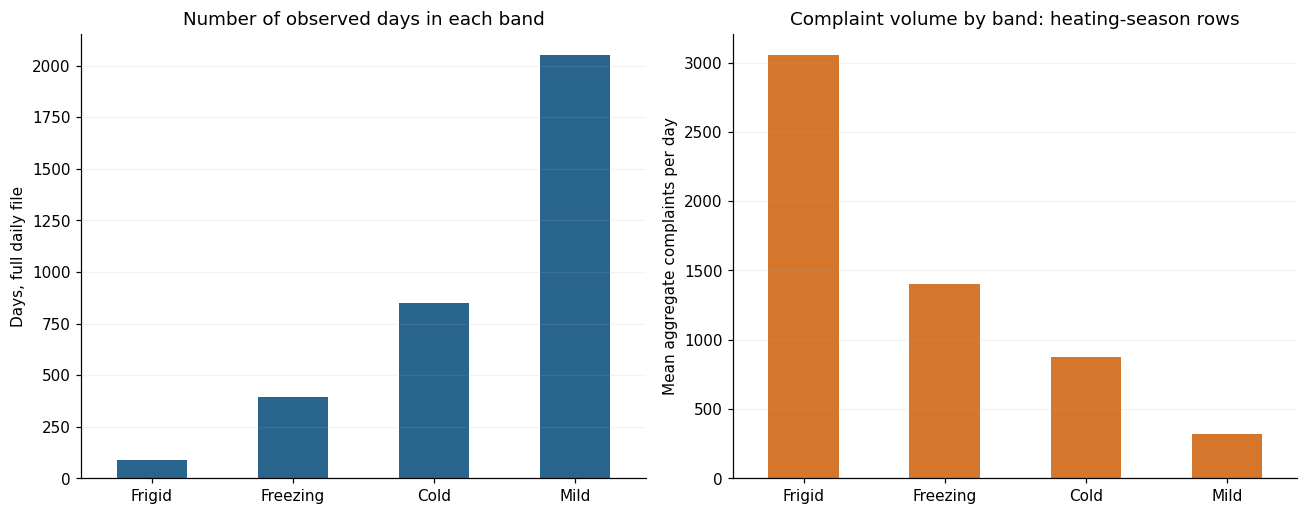

Days per band by year: partial first and last years are included.


weather_band,Frigid,Freezing,Cold,Mild
year,,,,
2017,4,12,38,129
2018,17,38,108,201
2019,10,53,92,209
2020,2,34,116,212
2021,3,51,88,222
2022,17,50,79,219
2023,2,21,111,231
2024,5,42,91,228
2025,12,61,81,211


In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
all_days['days'].plot.bar(ax=axes[0],rot=0,color='#28648b')
heating_days['mean_complaints_per_day'].plot.bar(ax=axes[1],rot=0,color='#d4772c')
axes[0].set(title='Number of observed days in each band',xlabel='',ylabel='Days, full daily file')
axes[1].set(title='Complaint volume by band: heating-season rows',xlabel='',ylabel='Mean aggregate complaints per day')
for ax in axes:
 ax.spines['top'].set_visible(False)
 ax.spines['right'].set_visible(False)
 ax.grid(axis='y',alpha=.15)
fig.tight_layout()
fig.savefig(OUT/'weather_band_summary.png',dpi=160,bbox_inches='tight')
plt.show()

year_band=days.groupby([days['day'].dt.year.rename('year'),'weather_band'],observed=False).size().unstack(fill_value=0)
print('Days per band by year: partial first and last years are included.')
display(year_band)
year_band.to_csv(OUT/'weather_band_days_by_year.csv')

## 3. Connect each property complaint date to weather and property details

**What this does:** loads the shared building-day table, joins weather by `day`, and joins the property list by `bbl`.
**Why:** citywide daily totals alone cannot identify which properties complained on cold dates.

Each BBL/date must occur once. A count of seven reports on a date still contributes **one complaint-day**.
The property-list join excludes BBLs outside the supplied property universe; it does not restrict the analysis to one borough.

In [4]:
import pandas as pd

bd = pd.read_csv(
    find_input("bbl_day_counts.csv"),
    dtype={"bbl": "string"},
    parse_dates=["day"]
)

if bd[["bbl", "day", "complaint_count"]].isna().any().any():
    raise ValueError("The building-day input has missing keys or counts.")
if bd.duplicated(["bbl", "day"]).any():
    raise ValueError("Expected one row per BBL/date in bbl_day_counts.csv.")
if not (bd["complaint_count"].gt(0) & bd["complaint_count"].mod(1).eq(0)).all():
    raise ValueError("Building-day complaint counts must be positive integers.")

print(f"Loaded {len(bd):,} rows")
display(bd.head())

Loaded 1,267,474 rows


,bbl,day,complaint_count
0,1000020001,2019-12-15,1
1,1000020001,2022-12-24,7
2,1000020001,2023-12-04,1
3,1000050010,2026-01-23,1
4,1000050010,2026-02-08,1


In [5]:
# Reuse the dates and weather bands already checked above.
weather = days.copy()

# Match each complaint date to that day's weather.
bd_weather = bd.merge(
    weather[["day", "TMIN", "weather_band"]],
    on="day",
    how="left",
    validate="many_to_one"
)

print("Rows without matching weather:",
      bd_weather["weather_band"].isna().sum())

if bd_weather["weather_band"].isna().any():
    raise ValueError("Some complaint dates lack observed weather; align the inputs before calculating rates.")

display(bd_weather.head())

Rows without matching weather: 0


,bbl,day,complaint_count,TMIN,weather_band
0,1000020001,2019-12-15,1,37,Cold
1,1000020001,2022-12-24,7,7,Frigid
2,1000020001,2023-12-04,1,42,Cold
3,1000050010,2026-01-23,1,14,Frigid
4,1000050010,2026-02-08,1,3,Frigid


In [6]:
properties = buildings.copy()
if properties["bbl"].isna().any() or properties["bbl"].duplicated().any():
    raise ValueError("The property list must contain one nonmissing row per BBL.")

# Attach property details using the matching property ID.
analysis_data = bd_weather.merge(
    properties[["bbl", "unitsres", "size", "yearbuilt", "yearalter1"]],
    on="bbl",
    how="inner",
    validate="many_to_one"
)

print(f"Complaint-date rows kept: {len(analysis_data):,}")
print(f"Rows outside the property list: {len(bd_weather) - len(analysis_data):,}")

display(analysis_data.head())

Complaint-date rows kept: 1,148,187
Rows outside the property list: 119,287


,bbl,day,complaint_count,TMIN,weather_band,unitsres,size,yearbuilt,yearalter1
0,1000050010,2026-01-23,1,14,Frigid,1320,1000+,1969.0,2013
1,1000050010,2026-02-08,1,3,Frigid,1320,1000+,1969.0,2013
2,1000070038,2021-02-05,1,37,Cold,3,3-9,1830.0,0
3,1000077501,2018-01-03,1,16,Frigid,42,30-99,1880.0,0
4,1000077501,2018-01-15,1,16,Frigid,42,30-99,1880.0,0


## 4. Compare complaint-day rates by property size

**Rate (%) = property-days with at least one qualifying complaint ÷ all eligible observed property-days × 100.**

For each size group, the denominator is its property count multiplied by the observed days in that weather band.
This includes zero-complaint properties and zero-complaint dates without constructing a huge property-by-date grid.
We restrict construction years to 1–2016 so the exploratory cohort predates the analysis window.

**Interpretation:** larger properties contain more households who could report a problem. A higher property complaint-day
rate alone does not establish worse heating per household. Read the printed percentages; color scales differ across charts.

In [7]:
# Select older properties and October-May dates.
cohort = properties.loc[
    properties["yearbuilt"].between(1, 2016)
].copy()

heating_weather = weather.loc[
    weather["day"].dt.month.isin([10, 11, 12, 1, 2, 3, 4, 5])
]

events = analysis_data.loc[
    analysis_data["bbl"].isin(cohort["bbl"]) &
    analysis_data["day"].isin(heating_weather["day"])
]

# Count all properties and dates, including those with no complaints.
size_order = ["3-9", "10-29", "30-99", "100-299", "300-999", "1000+"]
band_order = ["Frigid", "Freezing", "Cold", "Mild"]

property_counts = cohort.groupby("size").size().reindex(size_order)
day_counts = heating_weather.groupby(
    "weather_band", observed=False
).size().reindex(band_order)

# Count days with at least one complaint for each property.
complaint_days = events.groupby(
    ["size", "weather_band"], observed=True
).size().unstack(fill_value=0)

complaint_days = complaint_days.reindex(
    index=size_order, columns=band_order, fill_value=0
)

# Divide complaint-days by all possible property-days.
size_rates = (
    complaint_days.div(property_counts, axis=0)
    .div(day_counts, axis=1) * 100
)

print(f"Properties included: {len(cohort):,}")
print("Complaint-day rates (%)")
display(size_rates.round(2))

Properties included: 167,011
Complaint-day rates (%)


weather_band,Frigid,Freezing,Cold,Mild
size,,,,
3-9,0.21,0.11,0.07,0.03
10-29,1.94,0.91,0.58,0.24
30-99,5.81,2.91,1.81,0.68
100-299,6.48,3.11,1.89,0.78
300-999,6.51,3.09,2.05,1.09
1000+,11.51,6.10,3.99,2.17


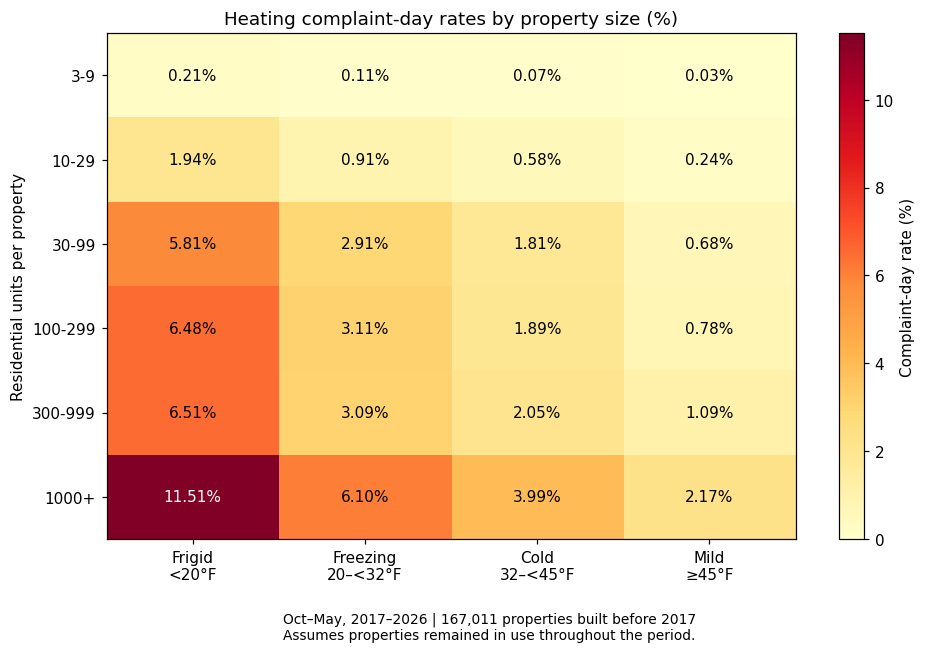

Chart and table saved in analysis_outputs/


In [8]:
from pathlib import Path
import matplotlib.pyplot as plt

out = Path("analysis_outputs")
out.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 6))

colors = ax.imshow(
    size_rates.to_numpy(),
    cmap="YlOrRd",
    vmin=0,
    aspect="auto"
)

ax.set_xticks(range(4))
ax.set_xticklabels([
    "Frigid\n<20°F", "Freezing\n20–<32°F",
    "Cold\n32–<45°F", "Mild\n≥45°F"
])

ax.set_yticks(range(len(size_rates)))
ax.set_yticklabels(size_rates.index)
ax.set_ylabel("Residential units per property")
ax.set_title("Heating complaint-day rates by property size (%)")

# Write the percentage inside each colored box.
for row in range(size_rates.shape[0]):
    for col in range(size_rates.shape[1]):
        value = size_rates.iloc[row, col]
        text_color = "white" if value > size_rates.max().max() * 0.6 else "black"
        ax.text(
            col, row, f"{value:.2f}%",
            ha="center", va="center", color=text_color
        )

fig.colorbar(colors, ax=ax, label="Complaint-day rate (%)")
fig.text(
    0.5, 0.02,
    "Oct–May, 2017–2026 | 167,011 properties built before 2017\n"
    "Assumes properties remained in use throughout the period.",
    ha="center", fontsize=9
)

fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(out / "size_weather_heatmap.png", dpi=200, bbox_inches="tight")
size_rates.to_csv(out / "size_weather_rates.csv")

plt.show()
print("Chart and table saved in analysis_outputs/")

## 5. Calculate cold-sensitivity multipliers

**What this does:** divides the Frigid complaint-day rate by the Mild complaint-day rate.
**Why:** it shows how much more often complaints were recorded on the coldest days within the same comparison window.
For example, the 30–99 unit group has rates of about 5.81% and 0.68%, with an 8.61× multiplier using full precision.
Ratios are calculated before rounding; dividing the rounded display values may give a slightly different answer.
A zero Mild baseline leaves the multiplier unavailable rather than producing an infinite score.

In [9]:
size_sensitivity = pd.DataFrame({
    "properties": property_counts,
    "mild_rate_pct": size_rates["Mild"],
    "frigid_rate_pct": size_rates["Frigid"],
    "frigid_vs_mild": size_rates["Frigid"].div(
        size_rates["Mild"].where(size_rates["Mild"] > 0)
    )
})

display(size_sensitivity.round(2))

size_sensitivity.to_csv(out / "size_cold_sensitivity.csv")
print("Saved: analysis_outputs/size_cold_sensitivity.csv")

,properties,mild_rate_pct,frigid_rate_pct,frigid_vs_mild
size,,,,
3-9,128780,0.03,0.21,7.73
10-29,20520,0.24,1.94,8.20
30-99,13697,0.68,5.81,8.61
100-299,3195,0.78,6.48,8.32
300-999,734,1.09,6.51,5.97
1000+,85,2.17,11.51,5.29


Saved: analysis_outputs/size_cold_sensitivity.csv


## 6. Compare construction eras

**What this does:** repeats the rate calculation for properties built before 1940, during 1940–1979, and during 1980–2016.
**Why:** it describes how reported problems differ across construction-era groups.
Compare both the absolute rate and the multiplier: a group with a low Mild baseline can have a large multiplier
while still having a lower Frigid rate than another group. These are descriptive, unadjusted comparisons.

In [10]:
# Put each property into a construction-year group.
era_order = ["Before 1940", "1940–1979", "1980–2016"]

cohort["era"] = pd.cut(
    cohort["yearbuilt"],
    bins=[0, 1940, 1980, 2017],
    labels=era_order,
    right=False
)

# Attach those groups to the complaint-day records.
era_events = events.merge(
    cohort[["bbl", "era"]],
    on="bbl",
    how="left",
    validate="many_to_one"
)

# Count all properties and the days with complaints.
era_property_counts = cohort.groupby("era", observed=False).size()

era_complaint_days = era_events.groupby(
    ["era", "weather_band"], observed=True
).size().unstack(fill_value=0)

era_complaint_days = era_complaint_days.reindex(
    index=era_order, columns=band_order, fill_value=0
)

# Calculate the same percentage as before.
era_rates = (
    era_complaint_days.div(era_property_counts, axis=0)
    .div(day_counts, axis=1) * 100
)

print("Complaint-day rates by construction year (%)")
display(era_rates.round(2))

era_rates.to_csv(out / "era_weather_rates.csv")

Complaint-day rates by construction year (%)


weather_band,Frigid,Freezing,Cold,Mild
era,,,,
Before 1940,1.08,0.54,0.35,0.13
1940–1979,1.32,0.65,0.40,0.16
1980–2016,0.57,0.22,0.12,0.05


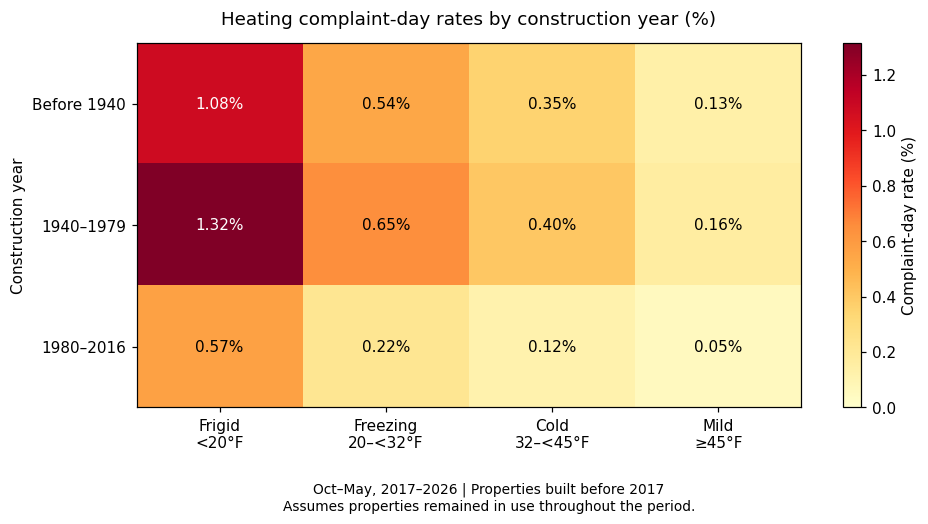

Saved: analysis_outputs/era_weather_heatmap.png


In [11]:
def draw_rate_heatmap(rates, title, row_label, filename):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    highest_rate = rates.max().max()

    colors = ax.imshow(
        rates.to_numpy(), cmap="YlOrRd", vmin=0, aspect="auto"
    )

    ax.set_xticks(range(4))
    ax.set_xticklabels([
        "Frigid\n<20°F", "Freezing\n20–<32°F",
        "Cold\n32–<45°F", "Mild\n≥45°F"
    ])

    ax.set_yticks(range(len(rates)))
    ax.set_yticklabels(rates.index)
    ax.set_ylabel(row_label)
    ax.set_title(title, pad=12)

    for row in range(rates.shape[0]):
        for col in range(rates.shape[1]):
            value = rates.iloc[row, col]
            color = "white" if value > highest_rate * 0.6 else "black"
            ax.text(
                col, row, f"{value:.2f}%",
                ha="center", va="center", color=color
            )

    fig.colorbar(colors, ax=ax, label="Complaint-day rate (%)")
    fig.text(
        0.5, 0.02,
        "Oct–May, 2017–2026 | Properties built before 2017\n"
        "Assumes properties remained in use throughout the period.",
        ha="center", fontsize=9
    )

    fig.tight_layout(rect=[0, 0.10, 1, 1])
    fig.savefig(out / filename, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out / filename)


draw_rate_heatmap(
    era_rates,
    "Heating complaint-day rates by construction year (%)",
    "Construction year",
    "era_weather_heatmap.png"
)

## 7. Compare recorded alteration history

**What this does:** classifies a recorded alteration as prior starting in the calendar year after its recorded year.
The numerator and denominator both use that historical classification. Properties with an alteration year earlier
than their construction year are excluded from this comparison only (795 properties in these inputs).

**Why:** a later alteration should not be treated as already completed on an earlier complaint date.
`yearalter1=0` means no recorded year in this extract, not proof that the property was never altered.
Alterations are not necessarily heating repairs. Age, size, reporting, and other differences can explain group differences;
this comparison does not estimate an alteration's causal effect. The current extract also does not establish when records became available.

In [12]:
# Exclude alteration dates earlier than construction.
alter_cohort = cohort.loc[
    cohort["yearalter1"].eq(0) |
    cohort["yearalter1"].ge(cohort["yearbuilt"])
].copy()

alter_order = [
    "Prior alteration recorded",
    "No prior alteration recorded"
]

# Assign each complaint-day using status at the start of its year.
alter_events = events.loc[
    events["bbl"].isin(alter_cohort["bbl"])
].copy()

prior = (
    alter_events["yearalter1"].gt(0) &
    alter_events["yearalter1"].lt(alter_events["day"].dt.year)
)

alter_events["alter_group"] = alter_order[1]
alter_events.loc[prior, "alter_group"] = alter_order[0]

# Count all properties in each group for each historical year.
prior_counts = {
    year: int(alter_cohort["yearalter1"].between(1, year - 1).sum())
    for year in heating_weather["day"].dt.year.unique()
}

exposure_days = heating_weather[["day", "weather_band"]].copy()
exposure_days[alter_order[0]] = exposure_days["day"].dt.year.map(prior_counts)
exposure_days[alter_order[1]] = (
    len(alter_cohort) - exposure_days[alter_order[0]]
)

alter_exposure = exposure_days.groupby(
    "weather_band", observed=False
)[alter_order].sum().T.reindex(columns=band_order)

# Divide complaint-days by all property-days in each group.
alter_complaint_days = alter_events.groupby(
    ["alter_group", "weather_band"], observed=True
).size().unstack(fill_value=0).reindex(
    index=alter_order, columns=band_order, fill_value=0
)

alter_rates = alter_complaint_days.div(alter_exposure) * 100

print(f"Properties included: {len(alter_cohort):,}")
print(f"Inconsistent dates excluded: {len(cohort) - len(alter_cohort):,}")
display(alter_rates.round(2))

alter_rates.to_csv(out / "alter_weather_rates.csv")
alter_exposure.to_csv(out / "alter_weather_property_days.csv")
alter_complaint_days.to_csv(out / "alter_weather_complaint_days.csv")

Properties included: 166,216
Inconsistent dates excluded: 795


weather_band,Frigid,Freezing,Cold,Mild
alter_group,,,,
Prior alteration recorded,1.76,0.83,0.51,0.20
No prior alteration recorded,0.85,0.43,0.28,0.11


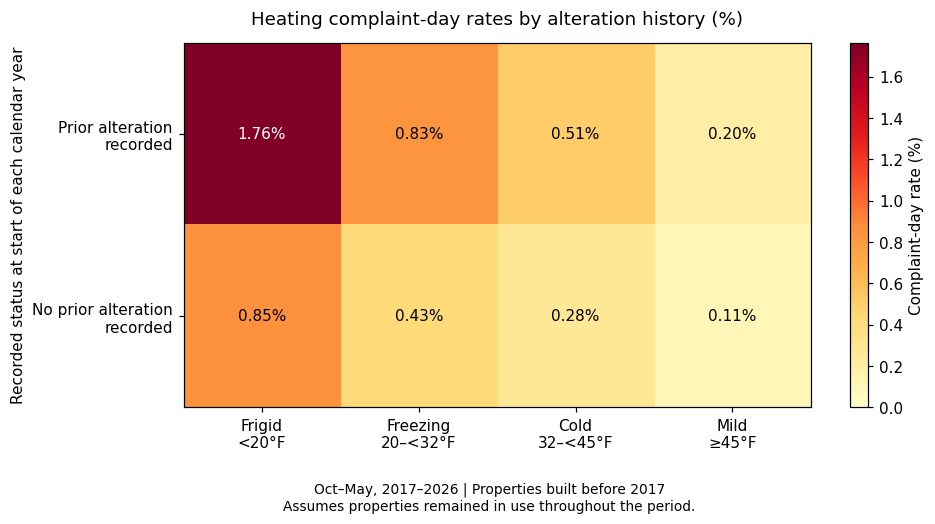

Saved: analysis_outputs/alter_weather_heatmap.png


In [13]:
draw_rate_heatmap(
    alter_rates.rename(index={
        "Prior alteration recorded": "Prior alteration\nrecorded",
        "No prior alteration recorded": "No prior alteration\nrecorded"
    }),
    "Heating complaint-day rates by alteration history (%)",
    "Recorded status at start of each calendar year",
    "alter_weather_heatmap.png"
)

## 8. Save each property's history by weather band

**What this does:** saves complaint-day counts, observed-day denominators, and rates for every property in the cohort,
including properties with zero complaints. `history_before` is the exclusive cutoff: only earlier dates contribute.

**Why:** it summarizes how often each property previously had a recorded complaint in each kind of weather.
For these files, the history ends on 2026-10-12 and `history_before` is 2026-10-13.
For a prediction on an earlier date, rebuild these histories using dates strictly before that prediction date.
The completed full-period histories cannot be used unchanged as features for a historical backtest.

In [14]:
# Count complaint-days for every property, including those with none.
property_counts_by_band = events.groupby(
    ["bbl", "weather_band"], observed=True
).size().unstack(fill_value=0).reindex(
    index=cohort["bbl"], columns=band_order, fill_value=0
)

property_rates = (
    property_counts_by_band.div(day_counts, axis=1) * 100
)

property_history = cohort.set_index("bbl")[
    ["size", "unitsres", "yearbuilt"]
].copy()

# Keep the counts and percentages for all four weather bands.
for band in band_order:
    name = band.lower()
    property_history[name + "_complaint_days"] = property_counts_by_band[band]
    property_history[name + "_observed_days"] = int(day_counts[band])
    property_history[name + "_rate_pct"] = property_rates[band]

# Record the date before which this history was collected.
property_history["history_before"] = (
    heating_weather["day"].max() + pd.Timedelta(days=1)
).date().isoformat()

property_history = property_history.reset_index()
property_history.to_csv(out / "property_weather_history.csv", index=False)

print(f"Properties saved: {len(property_history):,}")

display(property_history[[
    "bbl", "frigid_complaint_days", "frigid_observed_days",
    "frigid_rate_pct", "mild_rate_pct"
]].head().round(2))

Properties saved: 167,011


,bbl,frigid_complaint_days,frigid_observed_days,frigid_rate_pct,mild_rate_pct
0,1000050010,2,88,2.27,0.00
1,1000070038,0,88,0.00,0.00
2,1000077501,4,88,4.55,0.00
3,1000087501,0,88,0.00,0.00
4,1000110010,1,88,1.14,0.23


## 9. Describe chronic and cold-concentrated reporting patterns

These are **exploratory working labels**, not validated heating failures or model predictions:

- **Chronic:** Mild complaint-day rate ≥5%, with Mild complaints in at least three heating seasons.
- **Cold-concentrated:** at least five Frigid complaint-days across at least two heating seasons, and either
  a Frigid/Mild multiplier ≥3 or zero recorded Mild complaint-days.
- A property can satisfy both rules; the exported category records that overlap separately.
- Zero qualifying complaint-days gives “No recorded complaints”; one to four gives “Limited complaint history.”
  Remaining properties without either pattern are “Other complaint pattern.”

**Why:** the labels distinguish persistent reporting on Mild days from a pattern concentrated on the coldest dates.
No recorded complaints does not prove there were no heating problems. Thresholds are explicit and can be evaluated by the team later.

In [15]:
property_profiles = property_history.copy()

# Leave the multiplier blank when the Mild baseline is zero.
property_profiles["frigid_vs_mild"] = (
    property_profiles["frigid_rate_pct"].div(
        property_profiles["mild_rate_pct"].where(
            property_profiles["mild_rate_pct"] > 0
        )
    )
)

# Count separate heating seasons with complaints.
season_events = events[["bbl", "day", "weather_band"]].copy()
season_events["season"] = (
    season_events["day"].dt.year -
    season_events["day"].dt.month.le(5).astype(int)
)

for band in ["Mild", "Frigid"]:
    seasons = season_events.loc[
        season_events["weather_band"].eq(band)
    ].groupby("bbl")["season"].nunique()

    property_profiles[band.lower() + "_complaint_seasons"] = (
        property_profiles["bbl"].map(seasons).fillna(0).astype(int)
    )

# Apply the working rules.
chronic = (
    property_profiles["mild_rate_pct"].ge(5) &
    property_profiles["mild_complaint_seasons"].ge(3)
)

cold = (
    property_profiles["frigid_complaint_days"].ge(5) &
    property_profiles["frigid_complaint_seasons"].ge(2) &
    (
        property_profiles["frigid_vs_mild"].ge(3) |
        property_profiles["mild_complaint_days"].eq(0)
    )
)

total_days = property_profiles[
    [band.lower() + "_complaint_days" for band in band_order]
].sum(axis=1)

property_profiles["pattern"] = "Other complaint pattern"
property_profiles.loc[total_days.lt(5), "pattern"] = "Limited complaint history"
property_profiles.loc[total_days.eq(0), "pattern"] = "No recorded complaints"
property_profiles.loc[chronic & ~cold, "pattern"] = "Chronic pattern"
property_profiles.loc[cold & ~chronic, "pattern"] = "Cold-concentrated pattern"
property_profiles.loc[chronic & cold, "pattern"] = "Chronic + cold-concentrated"

property_profiles.to_csv(out / "property_complaint_patterns.csv", index=False)

display(
    property_profiles["pattern"].value_counts()
    .rename("properties").to_frame()
)

,properties
pattern,
No recorded complaints,106195
Limited complaint history,30929
Other complaint pattern,20603
Cold-concentrated pattern,8821
Chronic pattern,232
Chronic + cold-concentrated,231


## 10. Save the combined sensitivity table and pattern counts

**What this does:** puts all three group comparisons and their cold-versus-Mild multipliers in one CSV,
then saves mutually exclusive property-pattern counts.
**Why:** the presentation and modeling teammates can use consistent summaries from the same analysis.

In [16]:
summary_parts = []

for group_type, rates in [
    ("Size", size_rates),
    ("Construction year", era_rates),
    ("Alteration history", alter_rates)
]:
    table = rates.rename(columns={
        band: band.lower() + "_rate_pct" for band in band_order
    }).copy()

    # Compare each colder band's rate with its Mild baseline.
    for band in ["Frigid", "Freezing", "Cold"]:
        table[band.lower() + "_vs_mild"] = rates[band].div(
            rates["Mild"].where(rates["Mild"] > 0)
        )

    table["group_type"] = group_type
    table["group"] = table.index.astype(str)
    summary_parts.append(table.reset_index(drop=True))

group_sensitivity = pd.concat(summary_parts, ignore_index=True)
group_sensitivity.to_csv(out / "group_cold_sensitivity.csv", index=False)

property_profiles["pattern"].value_counts().rename(
    "properties"
).to_csv(out / "property_pattern_counts.csv")

display(group_sensitivity[[
    "group_type", "group", "mild_rate_pct",
    "frigid_rate_pct", "frigid_vs_mild"
]].round(2))

weather_band,group_type,group,mild_rate_pct,frigid_rate_pct,frigid_vs_mild
0,Size,3-9,0.03,0.21,7.73
1,Size,10-29,0.24,1.94,8.20
2,Size,30-99,0.68,5.81,8.61
3,Size,100-299,0.78,6.48,8.32
4,Size,300-999,1.09,6.51,5.97
5,Size,1000+,2.17,11.51,5.29
6,Construction year,Before 1940,0.13,1.08,8.00
7,Construction year,1940–1979,0.16,1.32,8.15
8,Construction year,1980–2016,0.05,0.57,11.09
9,Alteration history,Prior alteration recorded,0.20,1.76,8.78


## 11. Save the handoff note

**What this does:** writes the methods note that accompanies the CSV tables and PNG charts.
**Why:** teammates need the rate definition, cohort assumptions, and pattern rules to interpret the results.
There are 19 result files for these inputs; the notebook is a separate source-code deliverable.

For slides, use the three `*_weather_heatmap.png` files. For all group comparisons, use
`group_cold_sensitivity.csv`. For property histories and exploratory labels, use
`property_weather_history.csv` and `property_complaint_patterns.csv`.

In [17]:
from pathlib import Path

out = Path("analysis_outputs")

notes = """HEATAHEAD — ANALYSIS HANDOFF

Inputs: days.csv, buildings.csv, bbl_day_counts.csv.
Coverage: all five boroughs; available weather dates through 2026-10-12.
Main comparisons use October-May and properties built before 2017.
We assume these properties remained active and covered throughout.
BBL identifies a property/lot, which can contain multiple buildings.

RATE DEFINITION
Complaint-days / eligible property-days * 100.
A property counts once per day even if it received multiple complaints.
Days and properties with zero complaints are included in denominators.
Weather bands use TMIN: Frigid <20, Freezing 20-<32, Cold 32-<45, Mild >=45 F.

ALTERATION COMPARISON
Recorded alterations count as prior starting the following calendar year.
795 properties with alteration years before construction were excluded here.
Groups also differ in age and size; comparisons are descriptive.

EXPLORATORY PATTERN RULES
Chronic: Mild complaint-day rate >=5%, across >=3 heating seasons.
Cold-concentrated: >=5 Frigid complaint-days across >=2 heating seasons,
and Frigid/Mild rate >=3, or zero recorded Mild complaint-days.
Properties can match both patterns.
A zero Mild baseline leaves the raw multiplier blank.
No recorded complaints means no qualifying reports on selected dates.

USING THE HISTORY FILES
Histories summarize data through 2026-10-12.
For predictions on earlier dates, rebuild histories using only earlier data.
Pattern labels describe reporting history and are exploratory.

KEY FILES
*_weather_heatmap.png: charts for the presentation.
group_cold_sensitivity.csv: all group rates and weather multipliers.
property_weather_history.csv: individual property histories.
property_complaint_patterns.csv: histories with pattern labels.
property_pattern_counts.csv: counts in each pattern category.
"""

(out / "README_HANDOFF.txt").write_text(notes, encoding="utf-8")

print("Results and methods saved in:", out.resolve())


Results and methods saved in: /workspace/scratch/eea9cc0a0baa/hpd_work/notebook_review_run/analysis_outputs
